## Exercise 2

For this exercise , you will be working with the [Titanic Data Set from Kaggle](https://www.kaggle.com/c/titanic). This is a very famous data set and very often is a student's first step in Data Analytics! 

The Dataset has been given to you on D2L. You need to download the .csv file from your assignment folder. The above link is just for a reference story about the data. 


1- For this assignment, you need to perform explorotary data analysis and answer at least three hypotheses based on the dataset. You may need to use your knowledge of statiscts to analyze this data.

Here are three possible hypotheses that you can define for this dataset (you can define your own hypotheses as well):

- Determine if the survival rate is associated to the class of passenger
- Determine if the survival rate is associated to the gender
- Determine the survival rate is associated to the age



2- For each hypothesis, you need to make at least one plot. 

3- Write a summary of your findings in one page (e.g., summary statistics, plots) and submit the pdf file. Therefore, for part 2 of your assignment, you need to submit one jupyter notebook file and one pdf file.

This will be your first end to end data analysis project. For this assignment, you will be graded on you overall analysis, and your final report.

4- Push your code and project to github and provide the link to your code here.



Ensure that your github project is organized to at least couple of main folders, ensure that you have the README file as well:

- Src
- Data
- Docs
- Results

Read this link for further info:  https://gist.github.com/ericmjl/27e50331f24db3e8f957d1fe7bbbe510

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
pwd

'/Users/nhatha/Desktop/CPSC 4800/ASSIGNMENT/ASSIGNMENT2'

In [3]:
df = pd.read_csv("../Data/train.csv")

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [8]:
df["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [9]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [10]:
df["Age"].value_counts()

Age
24.00    30
22.00    27
18.00    26
28.00    25
19.00    25
         ..
24.50     1
0.67      1
0.42      1
34.50     1
74.00     1
Name: count, Length: 88, dtype: int64

## Hypothesis 1: Is survival rate associated with passenger class?

In [11]:
df.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

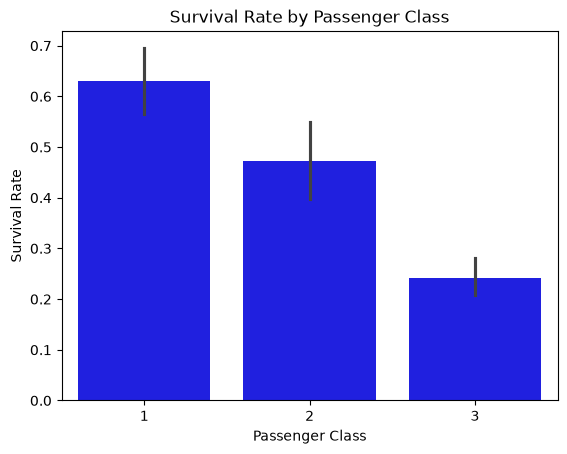

In [12]:
x = df["Pclass"]
y = df["Survived"]

sns.barplot(x="Pclass", y="Survived", data=df, color="b")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.savefig("../Results/Survival Rate by Passenger Class.png")
plt.show()

## Hypothesis 2: Is survival rate associated with gender ?

In [13]:
df.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

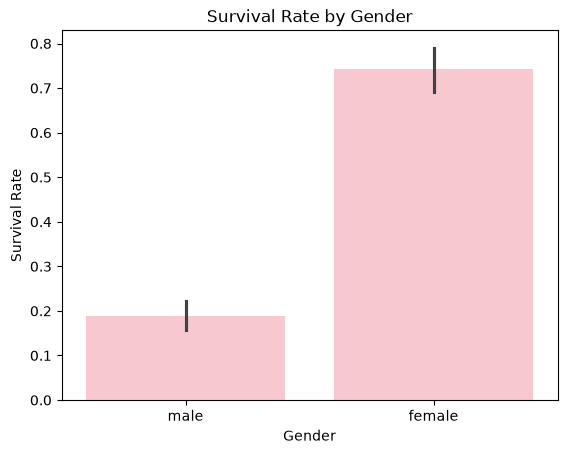

In [14]:
sns.barplot(x="Sex", y="Survived", data=df, color="pink")
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.savefig("../Results/Survival Rate by Gender.png")
plt.show()

In [15]:
# The percentage of male and female passengers survived

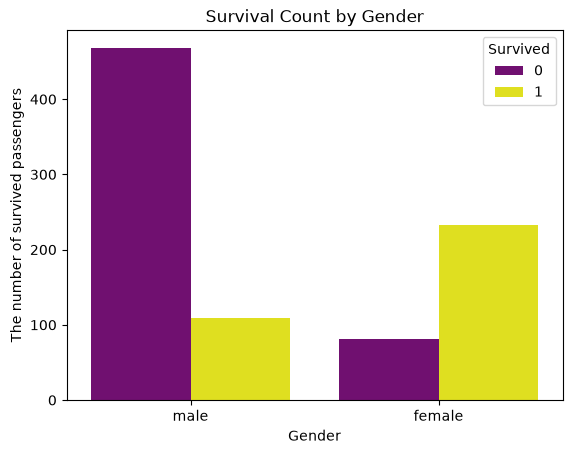

In [16]:
sns.countplot(x="Sex", hue="Survived", data=df, palette={0:"purple",1:"yellow"})
plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("The number of survived passengers")
plt.savefig("../Results/Survival Count by Gender.png")
plt.show()

## Hypothesis 3: Is survival rate associated with age ?

In [17]:
df.groupby("Survived")["Age"].value_counts().sort_index

<bound method Series.sort_index of Survived  Age  
0         21.00    19
          28.00    18
          18.00    17
          25.00    17
          22.00    16
                   ..
1         32.50     1
          12.00     1
          0.92      1
          37.00     1
          47.00     1
Name: count, Length: 142, dtype: int64>

In [18]:
df.groupby("Survived")["Age"].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

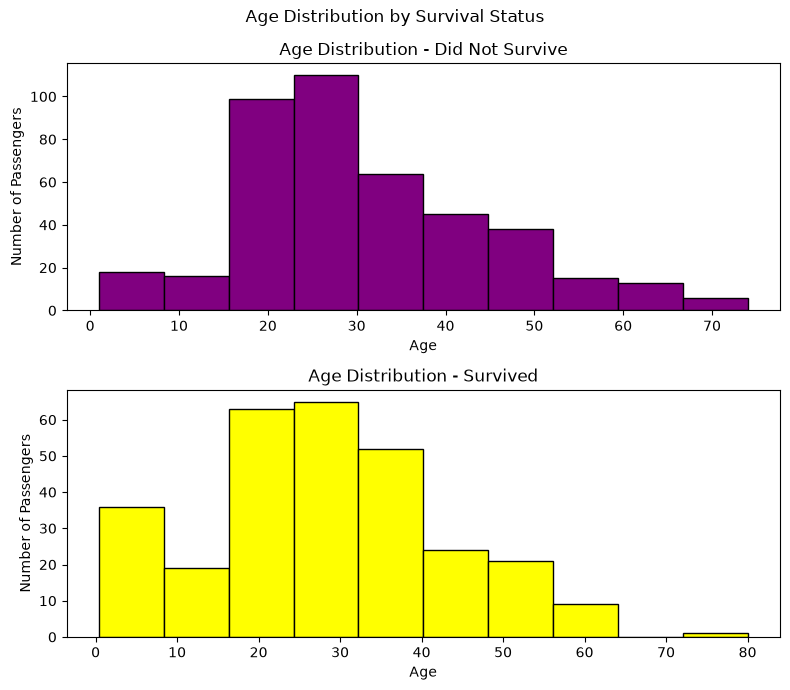

In [26]:
plt.figure(figsize=(8, 7))
#1st plot: Did not survive
plt.subplot(2,1,1)
plt.hist(df[df["Survived"]== 0]["Age"],  bins=10, color='purple', edgecolor='black')
plt.title("Age Distribution - Did Not Survive")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
# 2nd plot: Survived
plt.subplot(2, 1, 2)
plt.hist(df[df["Survived"] == 1]["Age"],
         bins=10, color='yellow', edgecolor='black')

plt.title("Age Distribution - Survived")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.suptitle("Age Distribution by Survival Status")
plt.tight_layout()
plt.savefig("../Results/Age Distribution by Survival Status.png")
plt.show()

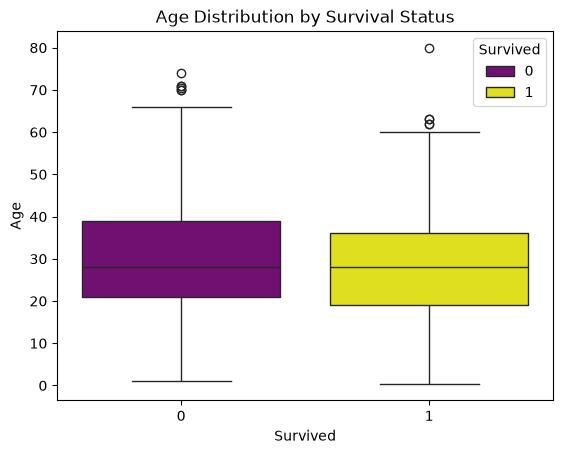

In [32]:
sns.boxplot(x="Survived", y="Age", data=df, hue='Survived', palette={0:"purple",1:"yellow"})
plt.title("Age Distribution by Survival Status")
plt.xlabel("Survived")
plt.ylabel("Age")
plt.show()

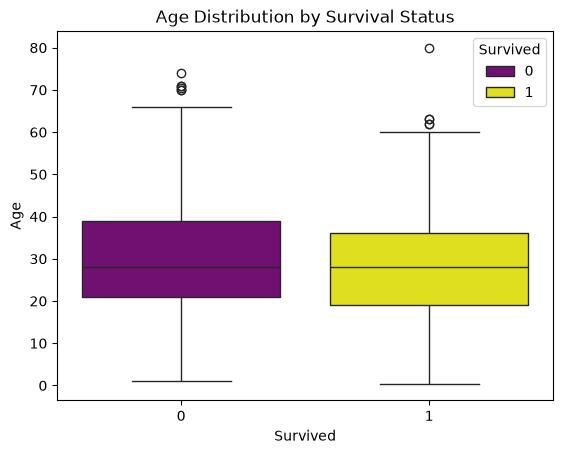

In [35]:
sns.boxplot(x="Survived", y="Age", data=df, hue='Survived', palette={0:"purple",1:"yellow"})
plt.title("Age Distribution by Survival Status")
plt.xlabel("Survived")
plt.ylabel("Age")
plt.show()